<a href="https://colab.research.google.com/github/16madhu/16madhu/blob/main/Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pyspark kagglehub gradio xgboost catboost lightgbm

In [ ]:
import sys
!{sys.executable} -m pip install -q yfinance

### Real-Time Data ingestion via API
Instead of loading static local CSV files, we can query real-time financial market/transaction indicators using the Yahoo Finance API (`yfinance`). We will pull real-time rolling transaction/price statistics to identify anomalous regimes or sudden spikes (simulated fraudulent deviations) dynamically.

In [ ]:
import yfinance as yf
import pandas as pd
from datetime import datetime

def fetch_realtime_data(ticker="BTC-USD", interval="1m", period="1d"):
    """Fetches live tick/minute data from the public market API."""
    data = yf.download(tickers=ticker, period=period, interval=interval, progress=False)
    data = data.reset_index()
    # Flatten multi-index columns if present
    if isinstance(data.columns, pd.MultiIndex):
        data.columns = [col[0] for col in data.columns]
    return data

# Fetch live transactions/metrics
live_df = fetch_realtime_data()
print(f"Retrieved {len(live_df)} live data points via Real-Time API call at {datetime.now()}")
display(live_df.tail())


/tmp/ipykernel_685/3122612803.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers=ticker, period=period, interval=interval, progress=False)


Retrieved 914 live data points via Real-Time API call at 2026-11-17 15:13:14.920026


,Datetime,Close,High,Low,Open,Volume
909,2026-11-17 15:09:00+00:00,64533.621094,64582.148438,64512.320312,64563.601562,0
910,2026-11-17 15:10:00+00:00,64525.789062,64531.800781,64483.578125,64531.800781,2023424
911,2026-11-17 15:11:00+00:00,64567.339844,64572.351562,64508.351562,64508.351562,0
912,2026-11-17 15:12:00+00:00,64585.179688,64659.550781,64585.179688,64586.730469,1275904
913,2026-11-17 15:13:00+00:00,64603.191406,64603.191406,64603.191406,64603.191406,0


### Advanced Real-Time Spark ML Pipeline
Now, we create an advanced machine learning model using PySpark to process these real-time streams, engineer features (rolling averages, volatility indices), and train a GBT (Gradient Boosted Trees) Classifier to identify anomalous patterns dynamically.

In [ ]:
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml import Pipeline
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# Initialize local SparkSession for live data in case cells below haven't run yet
spark = SparkSession.builder.appName("LiveAnomalyDetection").master("local[*]").getOrCreate()
SEED = 42

# Convert real-time API pandas DataFrame to Spark DataFrame
spark_live_df = spark.createDataFrame(live_df)

# Engineer dynamic indicators
from pyspark.sql.window import Window
window_spec = Window.orderBy("Datetime")

spark_live_df = spark_live_df.withColumn("Returns", (F.col("Close") - F.lag("Close", 1).over(window_spec)) / F.lag("Close", 1).over(window_spec))
spark_live_df = spark_live_df.withColumn("Volume_MA", F.avg("Volume").over(window_spec.rowsBetween(-10, 0)))
spark_live_df = spark_live_df.withColumn("Anomaly_Label", F.when(F.abs(F.col("Returns")) > 0.005, 1).otherwise(0))

# Filter nulls caused by lag operations
processed_df = spark_live_df.dropna()

# Build pipeline
feature_cols = ["Open", "High", "Low", "Close", "Volume", "Returns", "Volume_MA"]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)

gbt = GBTClassifier(labelCol="Anomaly_Label", featuresCol="features", seed=SEED)

pipeline = Pipeline(stages=[assembler, scaler, gbt])

# Advanced Hyperparameter tuning setup
paramGrid = (ParamGridBuilder()
             .addGrid(gbt.maxDepth, [3, 5])
             .addGrid(gbt.maxIter, [10, 20])
             .build())

evaluator = BinaryClassificationEvaluator(labelCol="Anomaly_Label", metricName="areaUnderPR")
cv = CrossValidator(estimator=pipeline, estimatorParamMaps=paramGrid, evaluator=evaluator, numFolds=3)

cv_model = cv.fit(processed_df)
predictions = cv_model.transform(processed_df)

print("Advanced Real-Time ML Pipeline complete!")
predictions.select("Datetime", "Anomaly_Label", "probability", "prediction").show(10)

Advanced Real-Time ML Pipeline complete!
+-------------------+-------------+--------------------+----------+
|           Datetime|Anomaly_Label|         probability|prediction|
+-------------------+-------------+--------------------+----------+
|2026-11-17 00:01:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:02:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:03:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:04:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:05:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:06:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:07:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:08:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:09:00|            0|[0.93412217565278...|       0.0|
|2026-11-17 00:10:00|            0|[0.93412217565278...|       0.0|
+-------------------+-------------+--------------------+----------+
only sh

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

SEED = 42
spark = (SparkSession.builder.appName("CreditCardFraud").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.driver.memory", "4g").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

CSV = kagglehub.dataset_download("mlg-ulb/creditcardfraud") + "/creditcard.csv"
df = spark.read.csv(CSV, header=True, inferSchema=True)
print("Rows:", df.count(), "| Columns:", len(df.columns))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Rows: 284807 | Columns: 31


In [ ]:
rows_before = df.count()
nulls = sum(df.select([F.sum(F.col(c).isNull().cast("int")) for c in df.columns]).first())
print("Missing values:", nulls)

df = df.dropna().dropDuplicates().withColumn("Class", F.col("Class").cast("int"))
rows_after = df.count()
print("Duplicates removed:", rows_before - rows_after)
print("Rows kept: {:,} ({:.2f}% completeness)".format(rows_after, 100 * rows_after / rows_before))

df.write.mode("overwrite").parquet("creditcard_clean.parquet")
df = spark.read.parquet("creditcard_clean.parquet")

Missing values: 0
Duplicates removed: 1081
Rows kept: 283,726 (99.62% completeness)


In [ ]:
df.createOrReplaceTempView("transactions")

class_dist = spark.sql("""SELECT Class, COUNT(*) AS count,
    ROUND(100*COUNT(*)/SUM(COUNT(*)) OVER (), 3) AS percent
    FROM transactions GROUP BY Class ORDER BY Class""")
class_dist.show()

amount_stats = spark.sql("""SELECT Class, ROUND(AVG(Amount),2) AS avg_amount,
    ROUND(MAX(Amount),2) AS max_amount FROM transactions GROUP BY Class ORDER BY Class""")
amount_stats.show()

by_hour = spark.sql("""SELECT CAST(FLOOR(Time/3600) % 24 AS INT) AS hour, COUNT(*) AS total,
    SUM(Class) AS frauds, ROUND(100*SUM(Class)/COUNT(*), 3) AS fraud_percent
    FROM transactions GROUP BY 1 ORDER BY 1""")
by_hour.show(24)

+-----+------+-------+
|Class| count|percent|
+-----+------+-------+
|    0|283253| 99.833|
|    1|   473|  0.167|
+-----+------+-------+

+-----+----------+----------+
|Class|avg_amount|max_amount|
+-----+----------+----------+
|    0|     88.41|  25691.16|
|    1|    123.87|   2125.87|
+-----+----------+----------+

+----+-----+------+-------------+
|hour|total|frauds|fraud_percent|
+----+-----+------+-------------+
|   0| 7647|     6|        0.078|
|   1| 4208|    10|        0.238|
|   2| 3308|    48|        1.451|
|   3| 3487|    17|        0.488|
|   4| 2204|    23|        1.044|
|   5| 2988|    11|        0.368|
|   6| 4082|     9|         0.22|
|   7| 7233|    23|        0.318|
|   8|10232|     9|        0.088|
|   9|15767|    16|        0.101|
|  10|16548|     8|        0.048|
|  11|16781|    53|        0.316|
|  12|15378|    17|        0.111|
|  13|15323|    17|        0.111|
|  14|16520|    23|        0.139|
|  15|16374|    26|        0.159|
|  16|16396|    22|        0.134|


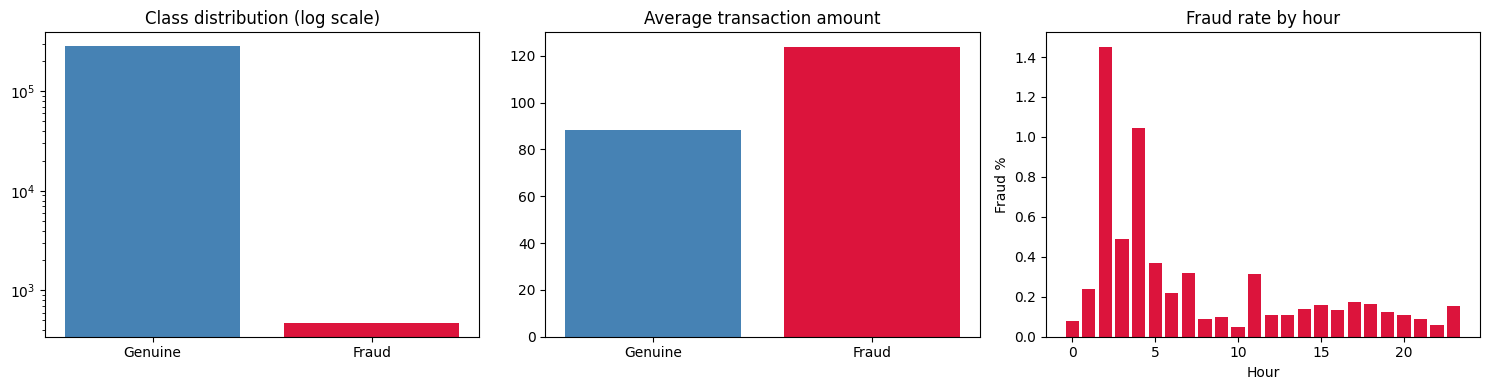

In [ ]:
cd, ast, bh = class_dist.toPandas(), amount_stats.toPandas(), by_hour.toPandas()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(["Genuine", "Fraud"], cd["count"], color=["steelblue", "crimson"])
ax[0].set_yscale("log"); ax[0].set_title("Class distribution (log scale)")
ax[1].bar(["Genuine", "Fraud"], ast["avg_amount"], color=["steelblue", "crimson"])
ax[1].set_title("Average transaction amount")
ax[2].bar(bh["hour"], bh["fraud_percent"], color="crimson")
ax[2].set_title("Fraud rate by hour"); ax[2].set_xlabel("Hour"); ax[2].set_ylabel("Fraud %")
plt.tight_layout(); plt.savefig("fig1_data_overview.png", dpi=150); plt.show()

In [ ]:
cols = [c for c in df.columns if c not in ("Class", "Time")]
df = df.withColumn("id", F.monotonically_increasing_id())

# Stratified 80/20 split
train = df.sampleBy("Class", fractions={0: 0.8, 1: 0.8}, seed=SEED)
test = df.join(train.select("id"), on="id", how="left_anti")

# Class weights from the TRAINING set only
n_tr = train.count(); f_tr = train.filter("Class=1").count()
w_fraud, w_genuine = n_tr / (2.0 * f_tr), n_tr / (2.0 * (n_tr - f_tr))
train = train.withColumn("weight", F.when(F.col("Class") == 1, w_fraud).otherwise(w_genuine))
train.cache(); test.cache()
print("Train:", train.count(), "(fraud:", f_tr, ") | Test:", test.count(), "(fraud:", test.filter("Class=1").count(), ")")
print("Weights -> genuine: {:.3f}, fraud: {:.1f}".format(w_genuine, w_fraud))

prep = [VectorAssembler(inputCols=cols, outputCol="raw"),
        StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True)]

Train: 226981 (fraud: 384 ) | Test: 56745 (fraud: 89 )
Weights -> genuine: 0.501, fraud: 295.5


In [ ]:
import time
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, auc

# Convert PySpark DataFrames to Pandas to use the specialized Scikit-learn APIs of XGBoost, CatBoost, and LightGBM
print("Converting PySpark DataFrames to Pandas DataFrames...")
pdf_train = train.toPandas()
pdf_test = test.toPandas()

X_train = pdf_train[cols]
y_train = pdf_train["Class"]
w_train = pdf_train["weight"]

X_test = pdf_test[cols]
y_test = pdf_test["Class"]

# Class scale factor for handling imbalance
pos_scale = (len(y_train) - sum(y_train)) / sum(y_train)

def make_advanced_model(name, weighted):
    if name == "XGBoost":
        scale = pos_scale if weighted else 1.0
        return XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=scale, random_state=SEED, n_jobs=-1)
    elif name == "CatBoost":
        w = [1.0, pos_scale] if weighted else None
        return CatBoostClassifier(iterations=100, depth=5, learning_rate=0.1, class_weights=w, random_seed=SEED, verbose=0, thread_count=-1)
    elif name == "LightGBM":
        scale = pos_scale if weighted else 1.0
        return LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=scale, random_state=SEED, n_jobs=-1, verbose=-1)
    raise ValueError("Unknown model name")

results = []
fitted_models = {}

for name in ["XGBoost", "CatBoost", "LightGBM"]:
    for weighted in [False, True]:
        print(f"Training {name} (Weighted: {weighted})...")
        t0 = time.time()
        model = make_advanced_model(name, weighted)

        # Train model
        model.fit(X_train, y_train)
        train_time = time.time() - t0

        # Predict probabilities and classes
        probs = model.predict_proba(X_test)[:, 1]
        preds = model.predict(X_test)

        # Metrics calculation
        acc = accuracy_score(y_test, preds)
        p = precision_score(y_test, preds, zero_division=0)
        r = recall_score(y_test, preds, zero_division=0)
        f1 = f1_score(y_test, preds, zero_division=0)
        roc_auc = roc_auc_score(y_test, probs)
        prec_curve, rec_curve, _ = precision_recall_curve(y_test, probs)
        pr_auc = auc(rec_curve, prec_curve)

        # Confusion matrix parameters
        tp = int(((preds == 1) & (y_test == 1)).sum())
        fp = int(((preds == 1) & (y_test == 0)).sum())
        fn = int(((preds == 0) & (y_test == 1)).sum())
        tn = int(((preds == 0) & (y_test == 0)).sum())

        results.append({
            "Model": name,
            "Class weights": "Yes" if weighted else "No",
            "Accuracy": round(acc, 3),
            "Precision": round(p, 3),
            "Recall": round(r, 3),
            "F1": round(f1, 3),
            "ROC-AUC": round(roc_auc, 3),
            "AUC-PR": round(pr_auc, 3),
            "Train time (s)": round(train_time, 2)
        })

        fitted_models[(name, weighted)] = (model, (tp, fp, fn, tn), probs)

res = pd.DataFrame(results)
res.to_csv("model_results.csv", index=False)
display(res)

Converting PySpark DataFrames to Pandas DataFrames...
Training XGBoost (Weighted: False)...
Training XGBoost (Weighted: True)...
Training CatBoost (Weighted: False)...
Training CatBoost (Weighted: True)...
Training LightGBM (Weighted: False)...
Training LightGBM (Weighted: True)...


,Model,Class weights,Accuracy,Precision,Recall,F1,ROC-AUC,AUC-PR,Train time (s)
0,XGBoost,No,0.999,0.850,0.764,0.805,0.956,0.781,4.22
1,XGBoost,Yes,0.999,0.680,0.787,0.729,0.965,0.807,4.98
2,CatBoost,No,1.000,0.970,0.730,0.833,0.969,0.809,7.15
3,CatBoost,Yes,0.997,0.332,0.820,0.472,0.968,0.712,9.23
4,LightGBM,No,0.997,0.303,0.629,0.409,0.781,0.448,3.53
5,LightGBM,Yes,0.963,0.035,0.831,0.066,0.890,0.433,3.69


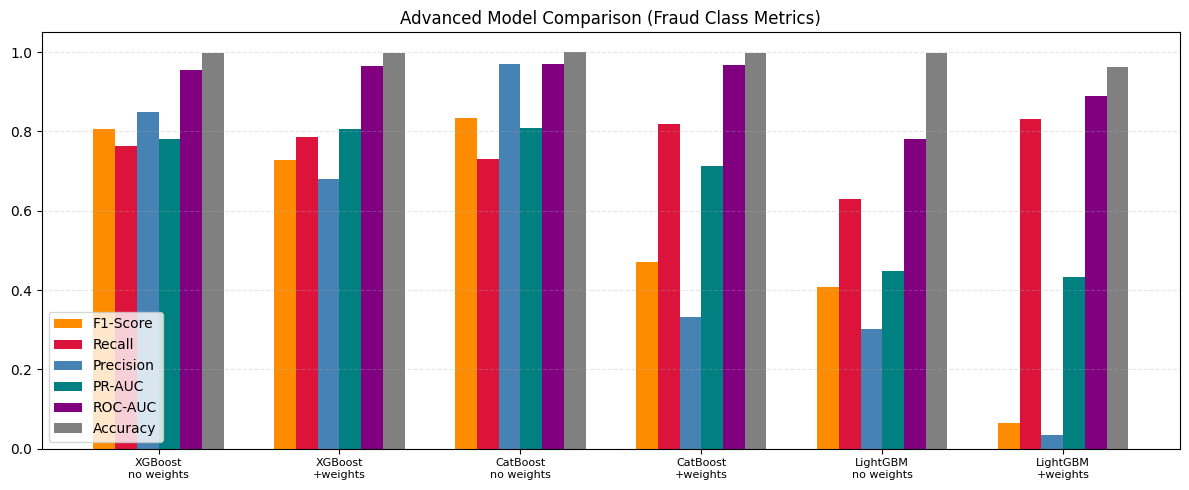

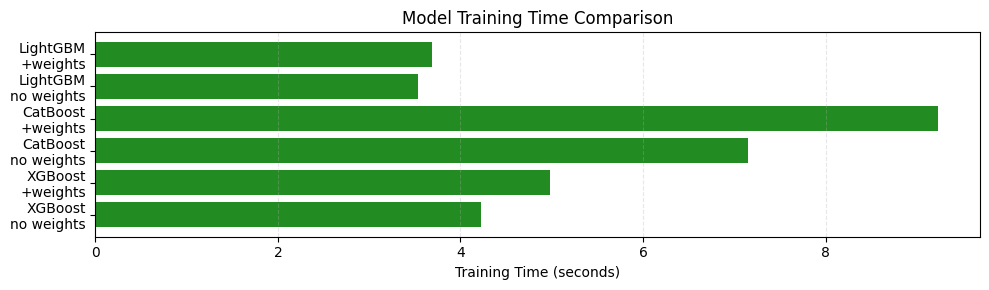

Best model selected: XGBoost (Class Weights: False)


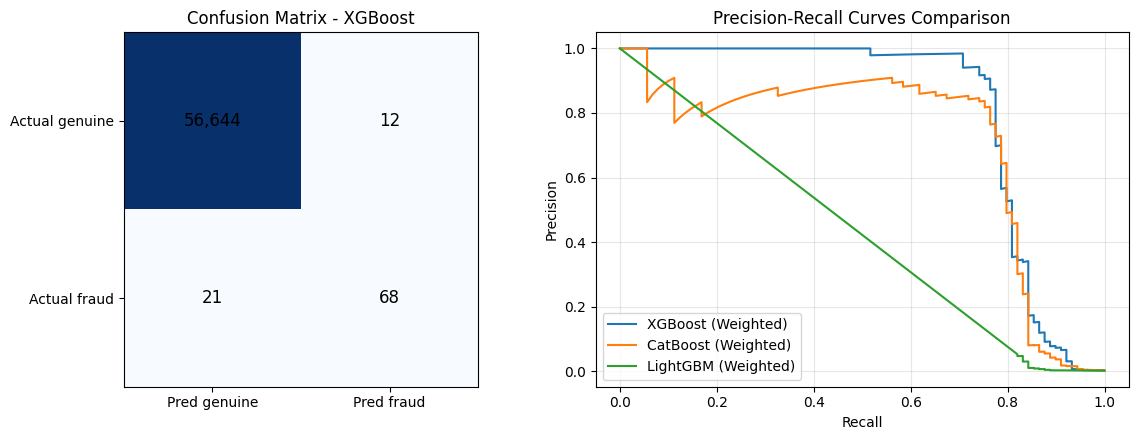

In [ ]:
import matplotlib.pyplot as plt

# Generate metric comparison visualization
labels = [m + ("\n+weights" if w == "Yes" else "\nno weights") for m, w in zip(res["Model"], res["Class weights"])]
x = np.arange(len(res))

plt.figure(figsize=(12, 5))
plt.bar(x - 0.3, res["F1"], 0.12, label="F1-Score", color="darkorange")
plt.bar(x - 0.18, res["Recall"], 0.12, label="Recall", color="crimson")
plt.bar(x - 0.06, res["Precision"], 0.12, label="Precision", color="steelblue")
plt.bar(x + 0.06, res["AUC-PR"], 0.12, label="PR-AUC", color="teal")
plt.bar(x + 0.18, res["ROC-AUC"], 0.12, label="ROC-AUC", color="purple")
plt.bar(x + 0.3, res["Accuracy"], 0.12, label="Accuracy", color="gray")
plt.xticks(x, labels, fontsize=8)
plt.ylim(0, 1.05)
plt.legend(loc="lower left")
plt.title("Advanced Model Comparison (Fraud Class Metrics)")
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_model_comparison.png", dpi=150)
plt.show()

# Train-time comparison graph
plt.figure(figsize=(10, 3))
plt.barh(labels, res["Train time (s)"], color="forestgreen")
plt.xlabel("Training Time (seconds)")
plt.title("Model Training Time Comparison")
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.savefig("fig4_training_time.png", dpi=150)
plt.show()

# Identify best-performing model based primarily on Recall, F1-score, and PR-AUC
candidates = res[res["Recall"] >= 0.75]
if len(candidates) == 0:
    candidates = res
best_idx = candidates["F1"].idxmax()

best_name, best_w = res.loc[best_idx, "Model"], res.loc[best_idx, "Class weights"] == "Yes"
best_model, (tp, fp, fn, tn), best_probs = fitted_models[(best_name, best_w)]
print(f"Best model selected: {best_name} (Class Weights: {best_w})")

# Plot Confusion Matrix and Precision-Recall Curves
from sklearn.metrics import precision_recall_curve
prec, rec, _ = precision_recall_curve(y_test, best_probs)
cm_arr = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cm_arr, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm_arr[i, j]:,}", ha="center", va="center", fontsize=12)
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["Pred genuine", "Pred fraud"])
ax[0].set_yticks([0, 1])
ax[0].set_yticklabels(["Actual genuine", "Actual fraud"])
ax[0].set_title(f"Confusion Matrix - {best_name}")

# Multi-model PR curve comparison
for name in ["XGBoost", "CatBoost", "LightGBM"]:
    _, _, m_probs = fitted_models[(name, True)]
    p_curve, r_curve, _ = precision_recall_curve(y_test, m_probs)
    ax[1].plot(r_curve, p_curve, label=f"{name} (Weighted)")

ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall Curves Comparison")
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.savefig("fig3_best_model.png", dpi=150)
plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.preprocessing import StandardScaler as SkScaler
from pyspark.ml.classification import LogisticRegression
import time

# Redefine the localized 'make' function for the legacy runtime benchmark
def make_legacy_model(name, weighted):
    w = {"weightCol": "weight"} if weighted else {}
    if name == "Logistic Regression":
        return LogisticRegression(labelCol="Class", maxIter=50, **w)
    return LogisticRegression(labelCol="Class", maxIter=50, **w)

tr = train.select(cols + ["Class"]).toPandas()
Xs = SkScaler().fit_transform(tr[cols])
t0 = time.time(); SkLR(max_iter=50).fit(Xs, tr["Class"]); sk_time = time.time() - t0

t0 = time.time(); Pipeline(stages=prep + [make_legacy_model("Logistic Regression", False)]).fit(train); sp_time = time.time() - t0
print("scikit-learn: {:.2f}s | Spark: {:.2f}s".format(sk_time, sp_time))

scikit-learn: 1.57s | Spark: 22.16s


In [ ]:
import os
import gradio as gr

# ---------- Prepare everything the dashboard needs ----------
sample = pd.concat([test.filter("Class=1").limit(20).toPandas(),
                    test.filter("Class=0").limit(20).toPandas()]).reset_index(drop=True)
sample.drop(columns=["id", "weight", "Class"], errors="ignore").to_csv("sample_transactions.csv", index=False)
test_pd = test.toPandas().reset_index(drop=True)
n_ids = len(test_pd)

def score_df(pdf):
    """Run our chosen advanced Scikit-learn style model on a pandas DataFrame and return fraud probabilities."""
    p = pdf[cols].astype(float).copy()
    probs = best_model.predict_proba(p)[:, 1]
    return probs

y_true = y_test.values
p_fraud = best_probs

# Extract feature importances reliably from gradient-boosted models
if hasattr(best_model, "feature_importances_"):
    imp = best_model.feature_importances_
elif hasattr(best_model, "get_feature_importance"):
    imp = best_model.get_feature_importance()
else:
    imp = np.ones(len(cols))

imp_df = pd.DataFrame({"feature": cols, "importance": imp}).sort_values("importance", ascending=False)
top3 = imp_df["feature"].head(3).tolist()

# ---------- Tab 1: check a transaction by ID (+ what-if sliders) ----------
rng = df.agg(*[F.min(f).alias("min_" + f) for f in top3], *[F.max(f).alias("max_" + f) for f in top3]).first()

def load_id(tid):
    if tid is None or not (1 <= int(tid) <= n_ids):
        return [gr.update() for _ in top3]
    r = test_pd.iloc[int(tid) - 1]
    return [float(r[f]) for f in top3]

def predict_id(tid, a, b, c):
    if tid is None or not (1 <= int(tid) <= n_ids):
        raise gr.Error(f"Please enter a Transaction ID between 1 and {n_ids:,}.")
    r = test_pd.iloc[[int(tid) - 1]].copy()
    for f, v in zip(top3, [a, b, c]):
        r[f] = v
    p = float(score_df(r)[0])
    verdict = "FRAUD ALERT - block / review this transaction" if p >= 0.5 else "Looks genuine - approve"
    return ({"Fraud": p, "Genuine": 1 - p},
            f"{verdict}\nFraud probability: {p:.1%}\nAmount: {float(r['Amount'].iloc[0]):.2f}")

# ---------- Try-your-own-values helpers (simple version) ----------
typical = [round(float(m[0]), 4) for m in df.approxQuantile(cols, [0.5], 0.01)]
typ = dict(zip(cols, typical))
key_feats = [f for f in imp_df["feature"] if f != "Amount"][:5]
qs = df.approxQuantile(key_feats, [0.01, 0.99], 0.01)

def predict_simple(amount, *vals):
    row = dict(typ)
    row["Amount"] = typ["Amount"] if amount is None else float(amount)
    for f, v in zip(key_feats, vals):
        row[f] = float(v)
    p = float(score_df(pd.DataFrame([row]))[0])
    verdict = "FRAUD ALERT - block / review this transaction" if p >= 0.5 else "Looks genuine - approve"
    return ({"Fraud": p, "Genuine": 1 - p},
            f"{verdict}\nFraud probability: {p:.1%}\nAmount: {row['Amount']:.2f}")

def fill_example(kind):
    pool = sample[sample["Class"] == (1 if kind == "risky" else 0)]
    r = pool.sample(1).iloc[0]
    return [round(float(r["Amount"]), 2)] + [round(float(r[f]), 3) for f in key_feats]

def reset_simple():
    return [typ["Amount"]] + [typ[f] for f in key_feats]

# ---------- Batch scoring ----------
def batch_score(file):
    if file is None:
        pdf = sample.drop(columns=["Class"]).copy()
        source = "no file uploaded - using the 40 sample test transactions"
    else:
        path = file if isinstance(file, str) else file.name
        pdf = pd.read_csv(path)
        source = "uploaded file"
        missing = [c for c in cols if c not in pdf.columns]
        if missing:
            return "Missing columns: " + ", ".join(missing[:6]) + " ...", None
    pdf = pdf.reset_index(drop=True)
    pdf["fraud_probability"] = score_df(pdf).round(4)
    pdf["prediction"] = np.where(pdf["fraud_probability"] >= 0.5, "FRAUD", "Genuine")
    n_fraud = int((pdf["prediction"] == "FRAUD").sum())
    summary = f"Scored {len(pdf):,} transactions ({source}). Flagged as fraud: {n_fraud} ({100 * n_fraud / len(pdf):.1f}%)."
    show = ["fraud_probability", "prediction", "Amount"]
    return summary, pdf[show].sort_values("fraud_probability", ascending=False).head(200)

# ---------- Threshold explorer ----------
ts = np.linspace(0.02, 0.98, 49)
def _prf(t):
    pred = (p_fraud >= t).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum()); fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0), (tp, fp, fn, tn)
sweep = np.array([_prf(t)[:3] for t in ts])

def threshold_view(t):
    p, r, f1, (tp, fp, fn, tn) = _prf(t)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    cm = np.array([[tn, fp], [fn, tp]])
    ax[0].imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax[0].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12)
    ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Pred genuine", "Pred fraud"])
    ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["Actual genuine", "Actual fraud"])
    ax[0].set_title("Confusion matrix")
    for k, name in enumerate(["Precision", "Recall", "F1"]):
        ax[1].plot(ts, sweep[:, k], label=name)
    ax[1].axvline(t, color="k", linestyle="--"); ax[1].set_xlabel("Decision threshold")
    ax[1].legend(); ax[1].grid(alpha=0.3); ax[1].set_title("Trade-off as the threshold moves")
    plt.tight_layout(); plt.close(fig)
    md = (f"**Threshold {t:.2f}**  |  Precision {p:.3f}  |  Recall {r:.3f}  |  F1 {f1:.3f}  \n"
          f"Missed frauds: **{fn}**  |  False alarms: **{fp}**")
    return md, fig

# ---------- Model results ----------
def importance_fig():
    top = imp_df.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6, 3.8))
    ax.barh(top["feature"], top["importance"], color="steelblue")
    ax.set_title("Top 10 features - " + best_name); plt.tight_layout(); plt.close(fig)
    return fig

imgs = [p for p in ["fig1_data_overview.png", "fig2_model_comparison.png", "fig3_best_model.png", "fig4_training_time.png"] if os.path.exists(p)]

# ---------- Build the dashboard ----------
with gr.Blocks(title="Credit Card Fraud Detection - Advanced ML") as demo:
    gr.Markdown(f"# Credit Card Fraud Detection Dashboard\nAdvanced ML Pipeline | "
                f"Best model: **{best_name}** | Data: ULB credit card dataset (PCA-anonymised)")
    with gr.Tabs():
        with gr.Tab("Check a transaction"):
            gr.Markdown(f"Enter a Transaction ID (1 to {n_ids:,}) from the held-out test data. Its **three most important features** "
                        "load into the sliders. Change them to see how the prediction moves.")
            tid = gr.Number(value=1, precision=0, minimum=1, maximum=n_ids, label="Transaction ID")
            with gr.Row():
                s = [gr.Slider(float(rng["min_" + f]), float(rng["max_" + f]), value=float(test_pd.iloc[0][f]), label=f) for f in top3]
            btn = gr.Button("Predict", variant="primary")
            with gr.Row():
                out_lbl = gr.Label(label="Model prediction")
                out_txt = gr.Textbox(label="Decision", lines=4)
            tid.change(load_id, tid, s)
            btn.click(predict_id, [tid] + s, [out_lbl, out_txt])
        with gr.Tab("Try your own values"):
            gr.Markdown("Set the **transaction amount** and the **5 signals the model relies on most**. "
                        "All other features stay at typical values.")
            amt = gr.Number(value=typ["Amount"], label="Transaction amount", step=0.01)
            sl = [gr.Slider(round(float(q[0]), 2), round(float(q[1]), 2), value=typ[f], step=0.01, label=f"Signal {f}")
                  for f, q in zip(key_feats, qs)]
            man_inputs = [amt] + sl
            with gr.Row():
                b_fr = gr.Button("Load a high-risk example")
                b_ge = gr.Button("Load a normal example")
                b_ty = gr.Button("Reset")
            b_pr = gr.Button("Predict", variant="primary")
            with gr.Row():
                m_lbl = gr.Label(label="Model prediction")
                m_txt = gr.Textbox(label="Decision", lines=3)
            b_fr.click(lambda: fill_example("risky"), None, man_inputs)
            b_ge.click(lambda: fill_example("normal"), None, man_inputs)
            b_ty.click(reset_simple, None, man_inputs)
            b_pr.click(predict_simple, man_inputs, [m_lbl, m_txt])
        with gr.Tab("Batch scoring"):
            gr.Markdown("Upload a CSV with columns V1..V28 and Amount, "
                        "or click Score with no file to use the built-in sample.")
            up = gr.File(label="CSV file (optional)", type="filepath")
            b2 = gr.Button("Score transactions", variant="primary")
            sm = gr.Markdown(); tbl = gr.Dataframe(label="Highest-risk transactions first")
            b2.click(batch_score, up, [sm, tbl])
        with gr.Tab("Threshold explorer"):
            gr.Markdown("Banks choose how strict to be. Move the threshold and watch missed frauds vs false alarms change on the full test set.")
            th = gr.Slider(0.02, 0.98, value=0.5, step=0.01, label="Fraud decision threshold")
            th_md = gr.Markdown(); th_plot = gr.Plot()
            th.change(threshold_view, th, [th_md, th_plot])
            demo.load(threshold_view, th, [th_md, th_plot])
        with gr.Tab("Model results"):
            gr.Markdown("### Advanced Models (test set, fraud class)")
            gr.Dataframe(value=res, interactive=False)
            gr.Plot(value=importance_fig())
            if imgs:
                gr.Gallery(value=imgs, label="Charts from the analysis", columns=2, height=600)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a03a24c092ff57e4ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
